In [ ]:
# 1. Install dependencies (Colab has most pre-installed; this pins what's needed)
!pip install -q xgboost shap

In [ ]:
## 2. Imports and reproducibility
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Ready. Upload The_IIoT_ID.csv in the next cell.')

Ready. Upload The_IIoT_ID.csv in the next cell.


In [ ]:
## 3. Upload the IIoT dataset
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
if not csv_files:
    raise ValueError('Please upload The_IIoT_ID.csv')
CSV_PATH = csv_files[0]
df = pd.read_csv(CSV_PATH, low_memory=False)
print('Dataset shape:', df.shape)
display(df.head())
print('\nColumns:', df.columns.tolist()[-15:])

Saving The_IIoT_ID.csv to The_IIoT_ID.csv
Dataset shape: (30000, 312)


,ip.checksum,ip.checksum.status,ip.dsfield,ip.dsfield.dscp,ip.dsfield.ecn,ip.dst_host,ip.flags,ip.flags.df,ip.flags.mf,ip.flags.rb,...,frame.number,frame.offset_shift,frame.protocols,frame.time_delta,frame.time_delta_displayed,frame.time_epoch,frame.time_relative,frame.time,attack_label,attack_type
0,0x6a40,2,0x00,0,0,192.168.55.9,0x02,1,0,0,...,1,0.0,eth:ethertype:ip:tcp:mqtt,0.000000,0.000000,1.689072e+09,0.000000,"Jul 11, 2023 16:13:49.676689000 IST",1,ddos_mp
1,0xa3c4,2,0x00,0,0,192.168.55.165,0x02,1,0,0,...,2,0.0,eth:ethertype:ip:tcp,0.000183,0.000183,1.689072e+09,0.000183,"Jul 11, 2023 16:13:49.676872000 IST",1,ddos_mp
2,0x9254,2,0x00,0,0,192.168.55.133,0x02,1,0,0,...,3,0.0,eth:ethertype:ip:tcp:mqtt,0.000380,0.000380,1.689072e+09,0.000563,"Jul 11, 2023 16:13:49.677252000 IST",1,ddos_mp
3,0x86ea,2,0x00,0,0,192.168.55.9,0x02,1,0,0,...,4,0.0,eth:ethertype:ip:tcp,0.007208,0.007208,1.689072e+09,0.007771,"Jul 11, 2023 16:13:49.684460000 IST",1,ddos_mp
4,0x6a40,2,0x00,0,0,192.168.55.9,0x02,1,0,0,...,5,0.0,eth:ethertype:ip:tcp:mqtt,0.493380,0.493380,1.689072e+09,0.501151,"Jul 11, 2023 16:13:50.177840000 IST",1,ddos_mp



Columns: ['frame.cap_len', 'frame.encap_type', 'frame.ignored', 'frame.len', 'frame.marked', 'frame.number', 'frame.offset_shift', 'frame.protocols', 'frame.time_delta', 'frame.time_delta_displayed', 'frame.time_epoch', 'frame.time_relative', 'frame.time', 'attack_label', 'attack_type']


In [ ]:
from sklearn.model_selection import train_test_split

# Map columns from 'df' (The_IIoT_ID.csv) to the format expected by subsequent cells
# We will use 'attack_label' or 'attack_type' as our target column 'class'
# Let's map 'attack_label' to 'class' (e.g. 'normal' vs 'anomaly' / attack types)

work_df = df.copy()
# Standardize class naming expected by downstream analysis ('normal' vs 'anomaly')
work_df['class'] = work_df['attack_label'].apply(lambda x: 'normal' if x == 'normal' or x == 0 else 'anomaly')

# Keep the feature set similar or use all columns except structural and targets
# Downstream code expects columns: ['protocol_type', 'service', 'flag', 'class'] and numeric features
target_cols = ['attack_label', 'attack_type', 'class']

# Let's align features to make sure they exist. We map names if they exist,
# or keep the IIoT dataset structure. Let's rename key columns to fit downstream code:
rename_dict = {
    'frame.protocols': 'protocol_type',
    'frame.len': 'src_bytes',
    'frame.cap_len': 'dst_bytes',
    'frame.time_delta': 'duration'
}
work_df = work_df.rename(columns=rename_dict)

# Ensure default expected columns are present so later code does not crash
for col in ['protocol_type', 'service', 'flag']:
    if col not in work_df.columns:
        work_df[col] = 'unknown'

# Perform train/test split
train_df, test_df = train_test_split(work_df, test_size=0.2, random_state=42, stratify=work_df['class'])

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print(train_df['class'].value_counts())
display(train_df.head())

Train shape: (24000, 315)
Test shape : (6000, 315)
class
anomaly    12000
normal     12000
Name: count, dtype: int64


,ip.checksum,ip.checksum.status,ip.dsfield,ip.dsfield.dscp,ip.dsfield.ecn,ip.dst_host,ip.flags,ip.flags.df,ip.flags.mf,ip.flags.rb,...,duration,frame.time_delta_displayed,frame.time_epoch,frame.time_relative,frame.time,attack_label,attack_type,class,service,flag
12055,0x77e2,2.0,0x00,0.0,0.0,192.168.158.165,0x02,1.0,0.0,0.0,...,0.000080,0.000080,1.688554e+09,5.818540,"Jul 5, 2023 16:23:46.721384000 IST",1,port_scan,anomaly,unknown,unknown
13415,0xd4a3,2.0,0x00,0.0,0.0,192.168.158.133,0x02,1.0,0.0,0.0,...,0.000198,0.000198,1.688556e+09,47.295315,"Jul 5, 2023 16:52:15.285999000 IST",1,sybil,anomaly,unknown,unknown
18837,0xcd31,2.0,0x00,0.0,0.0,192.168.233.165,0x02,1.0,0.0,0.0,...,0.000090,0.000090,1.688628e+09,75720.886243,"Jul 6, 2023 12:43:06.078057000 IST",0,normal,normal,unknown,unknown
25269,0x87b5,2.0,0x00,0.0,0.0,192.168.55.165,0x02,1.0,0.0,0.0,...,0.000078,0.000078,1.688716e+09,163866.845465,"Jul 7, 2023 13:12:12.037279000 IST",0,normal,normal,unknown,unknown
20659,0x1fb1,2.0,0x00,0.0,0.0,192.168.233.9,0x02,1.0,0.0,0.0,...,0.009058,0.009058,1.688628e+09,75945.078909,"Jul 6, 2023 12:46:50.270723000 IST",0,normal,normal,unknown,unknown


In [ ]:
# 5a. Basic shape, dtypes, missing values, duplicate rows
print("Train info:")
train_df.info()
print("\nTest info:")
test_df.info()
print("\nMissing values (train):", train_df.isnull().sum().sum())
print("Missing values (test) :", test_df.isnull().sum().sum())
print("Duplicate rows (train):", train_df.duplicated().sum())
print("Duplicate rows (test) :", test_df.duplicated().sum())

display(train_df.describe())

Train info:
<class 'pandas.core.frame.DataFrame'>
Index: 24000 entries, 12055 to 6092
Columns: 315 entries, ip.checksum to flag
dtypes: float64(188), int64(13), object(114)
memory usage: 57.9+ MB

Test info:
<class 'pandas.core.frame.DataFrame'>
Index: 6000 entries, 10965 to 4555
Columns: 315 entries, ip.checksum to flag
dtypes: float64(188), int64(13), object(114)
memory usage: 14.5+ MB

Missing values (train): 5491680
Missing values (test) : 1372785
Duplicate rows (train): 0
Duplicate rows (test) : 0


,ip.ttl.lncb,ip.opt.len,ip.opt.ra,ip.opt.type,ip.opt.type.class,ip.opt.type.copy,ip.opt.type.number,ipv6.hlim,ipv6.nxt,ipv6.plen,...,frame.ignored,src_bytes,frame.marked,frame.number,frame.offset_shift,duration,frame.time_delta_displayed,frame.time_epoch,frame.time_relative,attack_label
count,19.0,6.0,6.0,6.0,6.0,6.0,6.0,188.000000,188.000000,188.000000,...,24000.0,24000.000000,24000.0,24000.000000,24000.0,24000.000000,24000.000000,2.400000e+04,24000.000000,24000.00000
mean,1.0,4.0,0.0,148.0,0.0,1.0,20.0,180.420213,26.287234,148.585106,...,0.0,82.938417,0.0,4011.667625,0.0,10.056921,10.056921,1.688694e+09,82708.745383,0.50000
std,0.0,0.0,0.0,0.0,0.0,0.0,0.0,105.826763,18.378156,231.229978,...,0.0,74.349311,0.0,4669.657310,0.0,893.388294,893.388294,1.869211e+05,126969.114278,0.50001
min,1.0,4.0,0.0,148.0,0.0,1.0,20.0,1.000000,0.000000,8.000000,...,0.0,34.000000,0.0,1.000000,0.0,-0.000001,-0.000001,1.688552e+09,0.000000,0.00000
25%,1.0,4.0,0.0,148.0,0.0,1.0,20.0,63.000000,17.000000,32.000000,...,0.0,66.000000,0.0,469.000000,0.0,0.000088,0.000088,1.688555e+09,39.746012,0.00000
50%,1.0,4.0,0.0,148.0,0.0,1.0,20.0,255.000000,17.000000,53.000000,...,0.0,66.000000,0.0,936.000000,0.0,0.000263,0.000263,1.688628e+09,116.149440,0.50000
75%,1.0,4.0,0.0,148.0,0.0,1.0,20.0,255.000000,17.000000,126.000000,...,0.0,103.000000,0.0,7546.250000,0.0,0.008394,0.008394,1.688716e+09,163543.640561,1.00000
max,1.0,4.0,0.0,148.0,0.0,1.0,20.0,255.000000,58.000000,1338.000000,...,0.0,1514.000000,0.0,15000.000000,0.0,88842.223891,88842.223891,1.689251e+09,432596.081062,1.00000


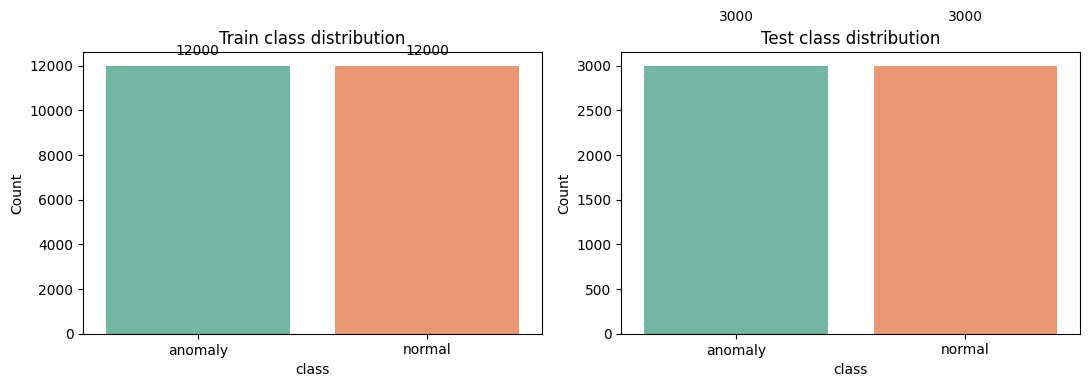

In [ ]:
# 5b. Class balance (normal vs anomaly)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, df, title in zip(axes, [train_df, test_df], ['Train', 'Test']):
    counts = df['class'].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Set2')
    ax.set_title(f'{title} class distribution')
    ax.set_ylabel('Count')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 500, str(v), ha='center')
plt.tight_layout()
plt.show()


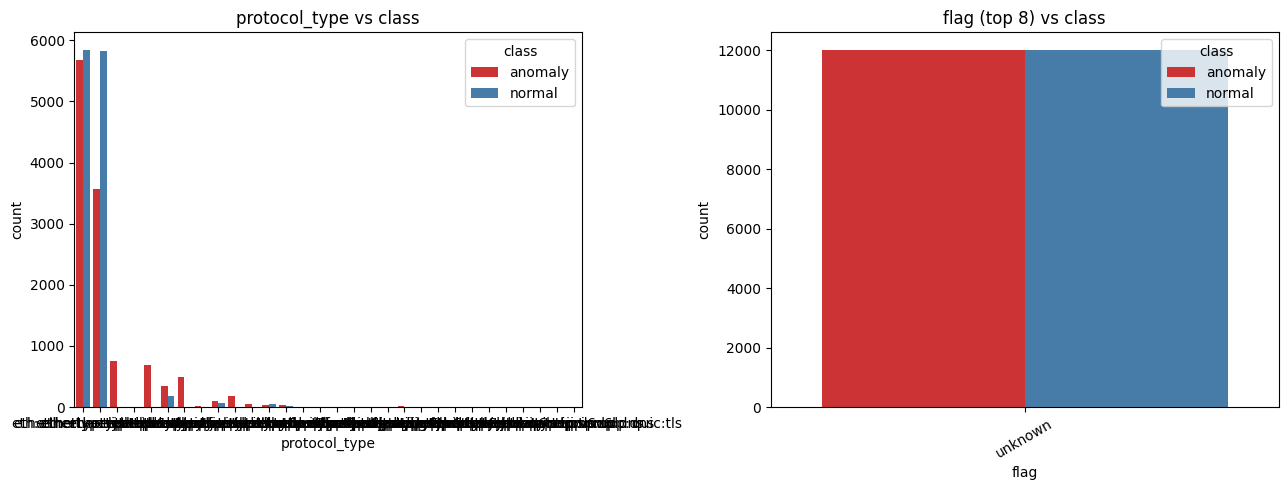

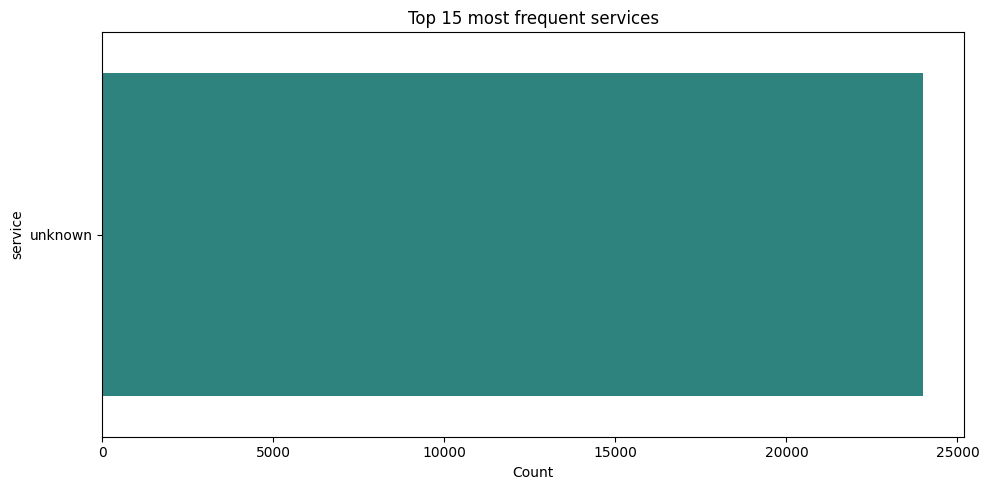

In [ ]:
# 5c. Categorical feature distributions vs class (protocol_type, flag)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=train_df, x='protocol_type', hue='class', ax=axes[0], palette='Set1')
axes[0].set_title('protocol_type vs class')

top_flags = train_df['flag'].value_counts().nlargest(8).index
sns.countplot(data=train_df[train_df['flag'].isin(top_flags)],
              x='flag', hue='class', ax=axes[1], palette='Set1')
axes[1].set_title('flag (top 8) vs class')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

# service has 60+ categories — show the top 15 by frequency
top_services = train_df['service'].value_counts().nlargest(15)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_services.values, y=top_services.index, palette='viridis')
plt.title('Top 15 most frequent services')
plt.xlabel('Count')
plt.tight_layout()
plt.show()


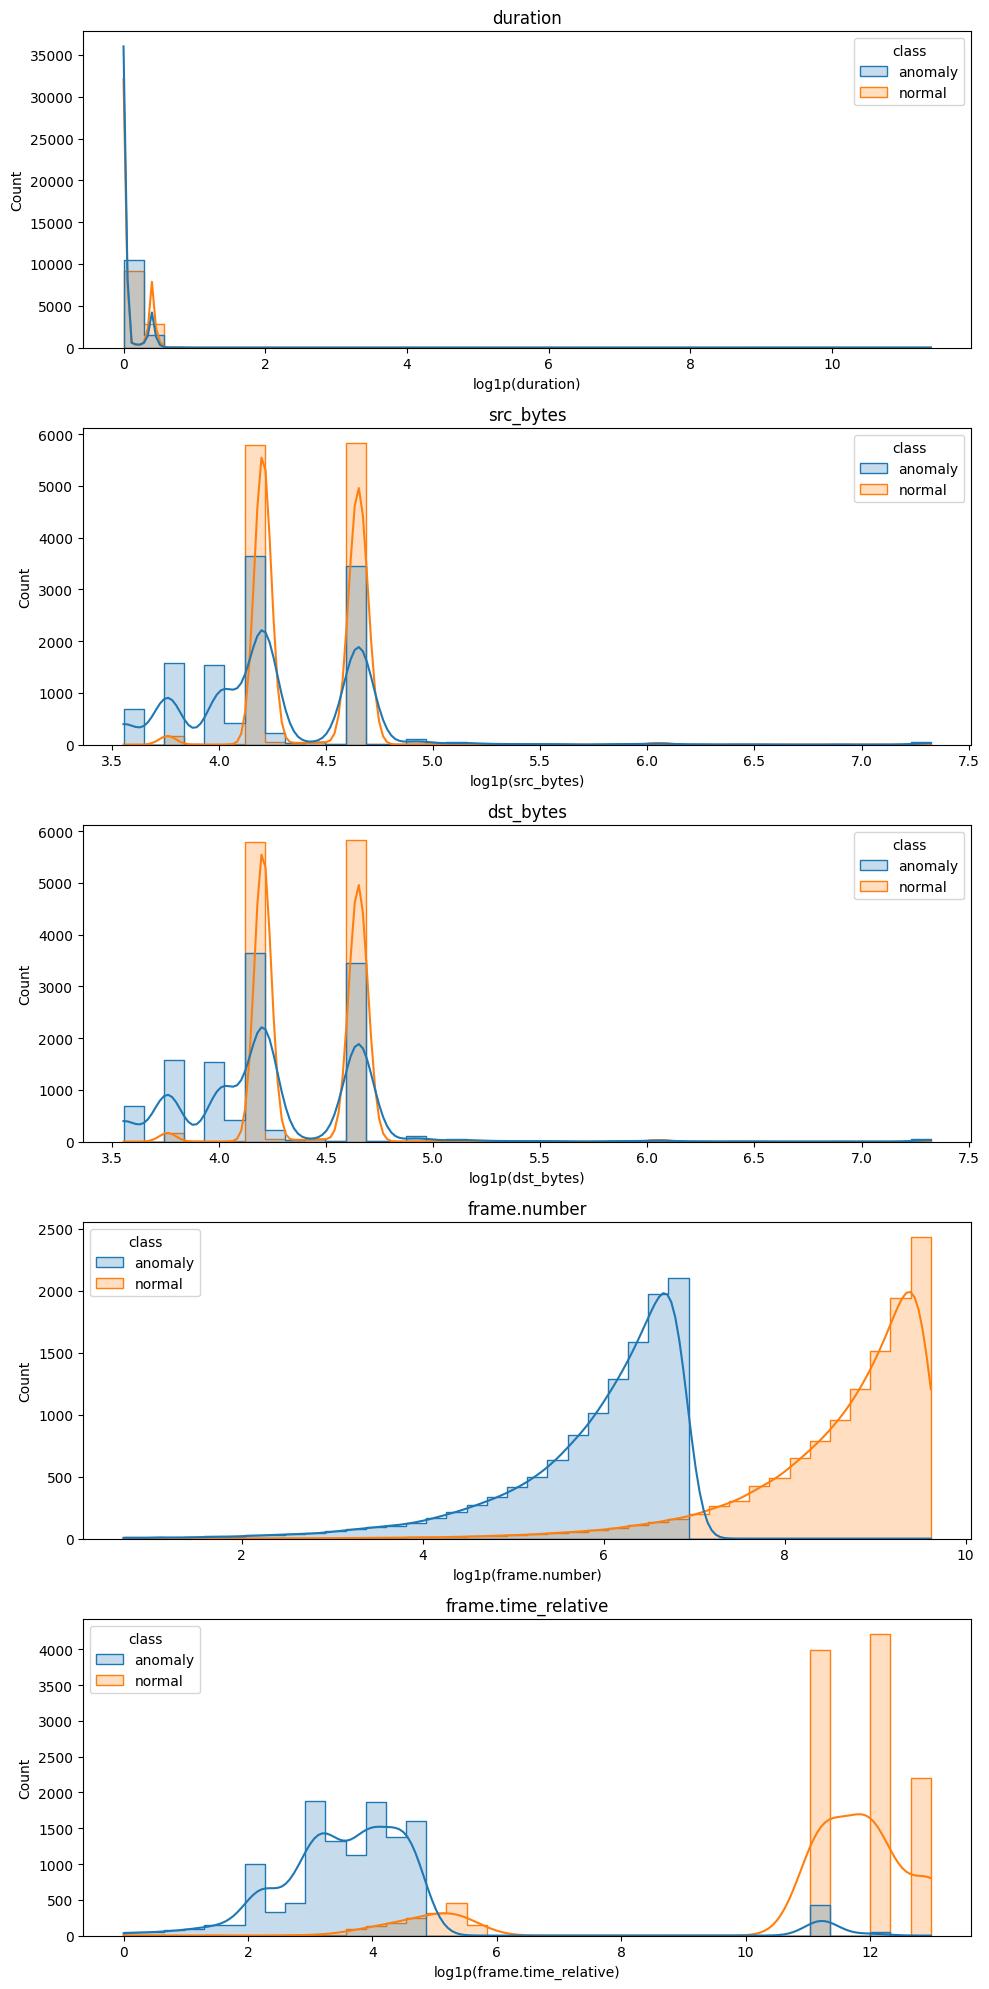

In [ ]:
# 5d. Key numeric feature distributions, split by class (Adapted for IIoT dataset)
numeric_features_of_interest = [
    'duration', 'src_bytes', 'dst_bytes', 'frame.number', 'frame.time_relative'
]

# Dynamic fallback to available numerical columns
actual_features = [f for f in numeric_features_of_interest if f in train_df.columns]

fig, axes = plt.subplots(len(actual_features), 1, figsize=(10, 4 * len(actual_features)))
if len(actual_features) == 1:
    axes = [axes]

for ax, feat in zip(axes, actual_features):
    data_to_plot = train_df.copy()
    if data_to_plot[feat].max() > 1000:
        data_to_plot[feat] = np.log1p(data_to_plot[feat])
        xlabel = f'log1p({feat})'
    else:
        xlabel = feat
    sns.histplot(data=data_to_plot, x=feat, hue='class', bins=40,
                 kde=True, element='step', ax=ax)
    ax.set_xlabel(xlabel)
    ax.set_title(feat)
plt.tight_layout()
plt.show()

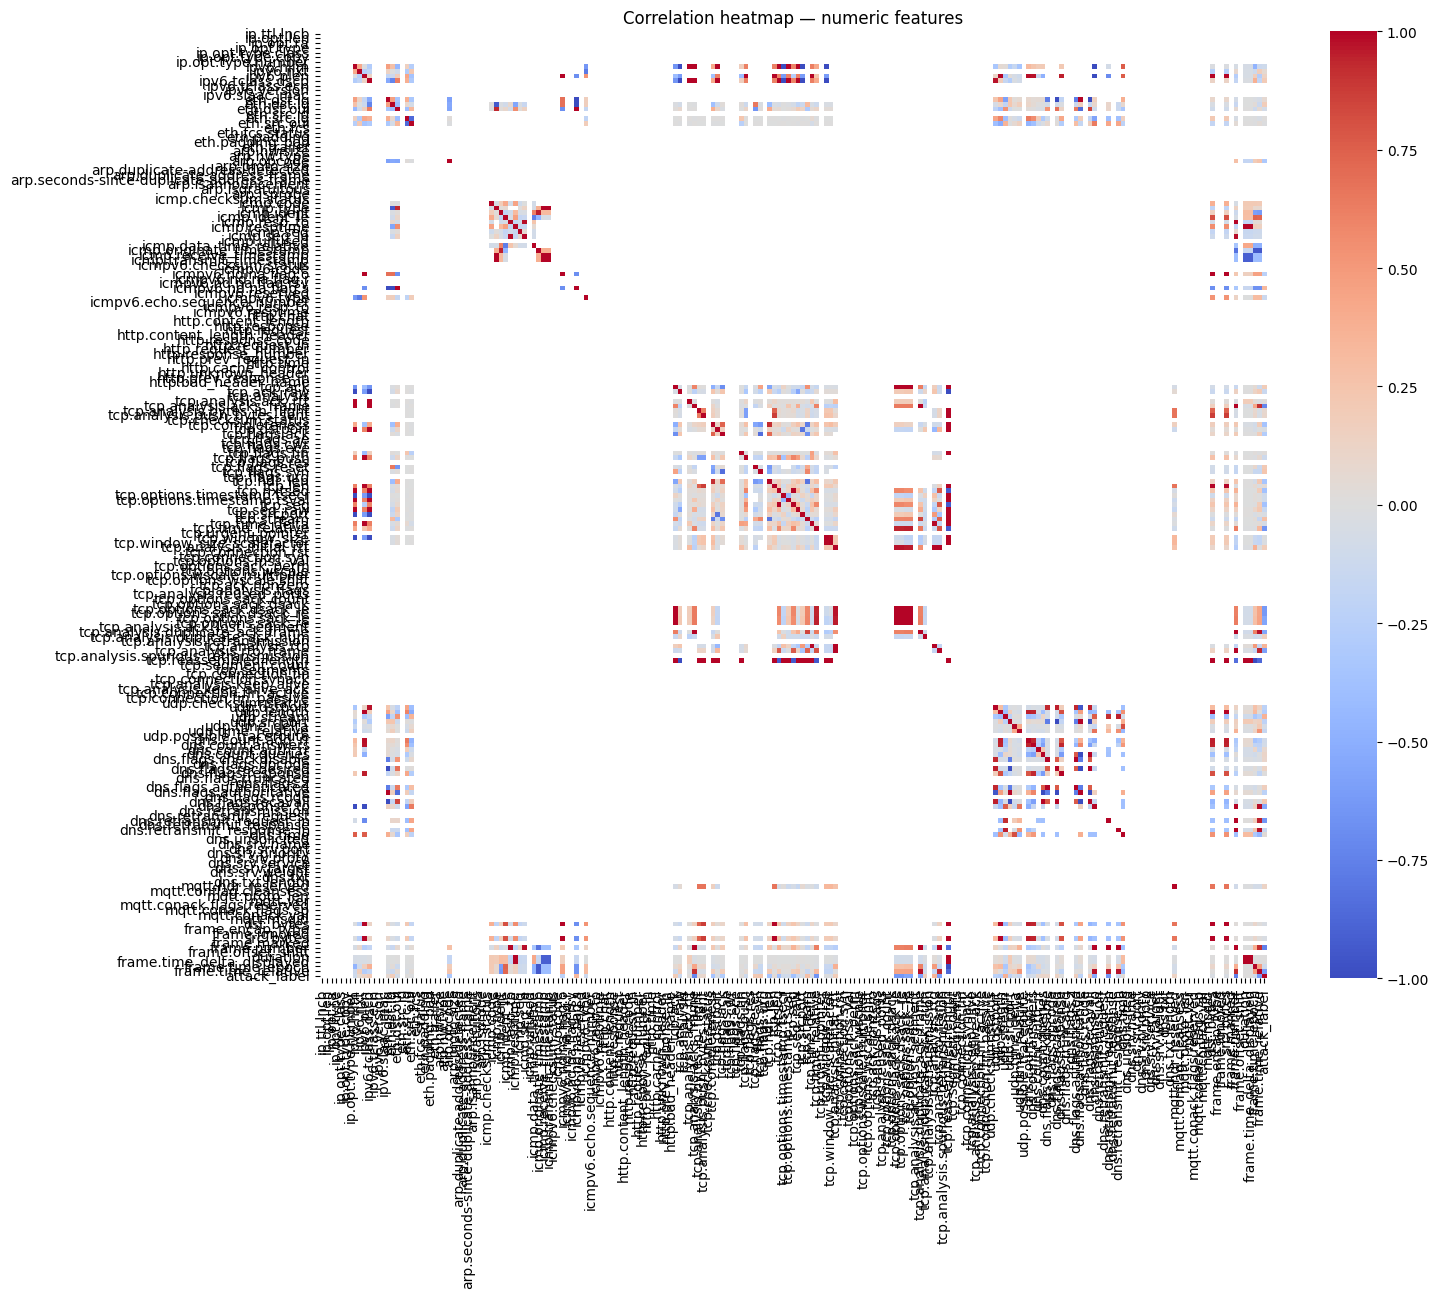

Top 10 most correlated feature pairs:
ipv6.plen                tcp.flags.push             1.0
udp.srcport              dns.flags.authoritative    1.0
dns.flags.authoritative  udp.srcport                1.0
tcp.flags.push           ipv6.plen                  1.0
ipv6.plen                dst_bytes                  1.0
dns.flags.recdesired     eth.dst.ig                 1.0
dst_bytes                ipv6.plen                  1.0
eth.dst.ig               dns.flags.recdesired       1.0
ipv6.hlim                tcp.analysis.ack_rtt       1.0
tcp.seq_raw              ipv6.hlim                  1.0
dtype: float64


In [ ]:
# 5e. Correlation heatmap among numeric features
numeric_df = train_df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True,
            xticklabels=True, yticklabels=True)
plt.title('Correlation heatmap — numeric features')
plt.tight_layout()
plt.show()

# Most correlated pairs (excluding self-correlation), useful to spot redundant features
corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0]
print("Top 10 most correlated feature pairs:")
print(corr_pairs.head(20)[::2])


In [ ]:
# 5f. Binary flag features: how often are they set, and does that relate to class? (Adapted for IIoT)
binary_like_cols = ['ip.flags.df', 'ip.flags.mf', 'tcp.flags.syn', 'tcp.flags.ack']
actual_binary_cols = [c for c in binary_like_cols if c in train_df.columns]

for col in actual_binary_cols:
    ct = pd.crosstab(train_df[col], train_df['class'], normalize='index')
    print(f"\n{col} vs class (row-normalized):")
    print(ct)


ip.flags.df vs class (row-normalized):
class         anomaly    normal
ip.flags.df                    
0            1.000000  0.000000
0,0          1.000000  0.000000
0,1          1.000000  0.000000
0.0          0.994449  0.005551
1            1.000000  0.000000
1.0          0.370293  0.629707

ip.flags.mf vs class (row-normalized):
class         anomaly    normal
ip.flags.mf                    
0            1.000000  0.000000
0,0          1.000000  0.000000
0.0          0.440044  0.559956

tcp.flags.syn vs class (row-normalized):
class           anomaly    normal
tcp.flags.syn                    
0.0            0.419279  0.580721
1.0            0.997780  0.002220

tcp.flags.ack vs class (row-normalized):
class           anomaly    normal
tcp.flags.ack                    
0.0            0.999180  0.000820
1.0            0.409846  0.590154


In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Dynamic column detection from current datasets
cat_cols = ['protocol_type', 'service', 'flag']
encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    # Convert columns to string to prevent mixed type issues
    train_df[c] = train_df[c].astype(str)
    test_df[c] = test_df[c].astype(str)
    combined = pd.concat([train_df[c], test_df[c]], axis=0)
    le.fit(combined)
    train_df[c] = le.transform(train_df[c])
    test_df[c]  = le.transform(test_df[c])
    encoders[c] = le

# Target formatting: normal -> 0, anomaly -> 1
target_le = LabelEncoder()
target_le.fit(['normal', 'anomaly'])
y_train = target_le.transform(train_df['class'])
y_test  = target_le.transform(test_df['class'])
class_names = target_le.classes_
print("Classes:", class_names)

# Separate features
X_train = train_df.drop(columns=['class', 'attack_label', 'attack_type'], errors='ignore')
X_test  = test_df.drop(columns=['class', 'attack_label', 'attack_type'], errors='ignore')

# Clean non-numeric/identifier columns before scaling
# Select only columns with numeric datatypes, or manually drop timestamps/hashes
X_train = X_train.select_dtypes(include=[np.number])
X_test = X_test[X_train.columns]

# Handle missing or infinite values safely
X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0)
X_test = X_test.replace([np.inf, -np.inf], np.nan).fillna(0)

feature_names = X_train.columns.tolist()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Features ready. Shape:", X_train_scaled.shape)

Classes: ['anomaly' 'normal']
Features ready. Shape: (24000, 203)


In [ ]:
# 7. Base learners for the stacking ensemble
rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1
)

xgb = XGBClassifier(
    n_estimators=300, max_depth=8, learning_rate=0.1,
    objective='binary:logistic', eval_metric='logloss',
    random_state=RANDOM_STATE, n_jobs=-1
)

def build_dnn(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model


In [ ]:
# 8. Generate out-of-fold (OOF) predictions from each base model -> meta-learner training data
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_rf  = np.zeros(len(y_train))
oof_xgb = np.zeros(len(y_train))
oof_dnn = np.zeros(len(y_train))

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train_scaled, y_train)):
    X_tr, X_val = X_train_scaled[tr_idx], X_train_scaled[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]

    rf_fold = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    rf_fold.fit(X_tr, y_tr)
    oof_rf[val_idx] = rf_fold.predict_proba(X_val)[:, 1]

    xgb_fold = XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                              objective='binary:logistic', eval_metric='logloss',
                              random_state=RANDOM_STATE, n_jobs=-1)
    xgb_fold.fit(X_tr, y_tr)
    oof_xgb[val_idx] = xgb_fold.predict_proba(X_val)[:, 1]

    dnn_fold = build_dnn(X_tr.shape[1])
    dnn_fold.fit(X_tr, y_tr, epochs=15, batch_size=512, verbose=0,
                 validation_data=(X_val, y_val))
    oof_dnn[val_idx] = dnn_fold.predict(X_val, verbose=0).ravel()

    print(f"Fold {fold+1}/5 done")

meta_X_train = np.column_stack([oof_rf, oof_xgb, oof_dnn])
print("Meta-learner training features shape:", meta_X_train.shape)


Fold 1/5 done
Fold 2/5 done
Fold 3/5 done
Fold 4/5 done
Fold 5/5 done
Meta-learner training features shape: (24000, 3)


In [ ]:
# 9. Fit the full base models on all training data (for final test-time predictions)
rf.fit(X_train_scaled, y_train)
xgb.fit(X_train_scaled, y_train)

dnn = build_dnn(X_train_scaled.shape[1])
history = dnn.fit(X_train_scaled, y_train, epochs=20, batch_size=512,
                   verbose=1, validation_split=0.1)


Epoch 1/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8905 - loss: 0.3049 - val_accuracy: 0.9646 - val_loss: 0.2325
Epoch 2/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9615 - loss: 0.1166 - val_accuracy: 0.9742 - val_loss: 0.1391
Epoch 3/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9712 - loss: 0.0809 - val_accuracy: 0.9762 - val_loss: 0.0910
Epoch 4/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9750 - loss: 0.0650 - val_accuracy: 0.9804 - val_loss: 0.0651
Epoch 5/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9742 - loss: 0.0610 - val_accuracy: 0.9779 - val_loss: 0.0557
Epoch 6/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9784 - loss: 0.0527 - val_accuracy: 0.9787 - val_loss: 0.0505
Epoch 7/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9789 - loss: 0.0489 - val_accuracy: 0.9833 - val_loss: 0.0444
Epoch 8/20
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9791 - loss: 0.0477 - val_accuracy: 0.9808 - val_lo

In [ ]:
# 10. Train the meta-learner (Logistic Regression) on OOF predictions
meta_learner = LogisticRegression(max_iter=1000)
meta_learner.fit(meta_X_train, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
# 11. Build stacked features for the held-out test set and get final predictions
test_rf_proba  = rf.predict_proba(X_test_scaled)[:, 1]
test_xgb_proba = xgb.predict_proba(X_test_scaled)[:, 1]
test_dnn_proba = dnn.predict(X_test_scaled, verbose=0).ravel()
meta_X_test = np.column_stack([test_rf_proba, test_xgb_proba, test_dnn_proba])
y_pred_proba = meta_learner.predict_proba(meta_X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

Accuracy : 1.0000
F1       : 1.0000
Precision: 1.0000
Recall   : 1.0000
ROC-AUC  : 1.0000

              precision    recall  f1-score   support

     anomaly       1.00      1.00      1.00      3000
      normal       1.00      1.00      1.00      3000

    accuracy                           1.00      6000
   macro avg       1.00      1.00      1.00      6000
weighted avg       1.00      1.00      1.00      6000



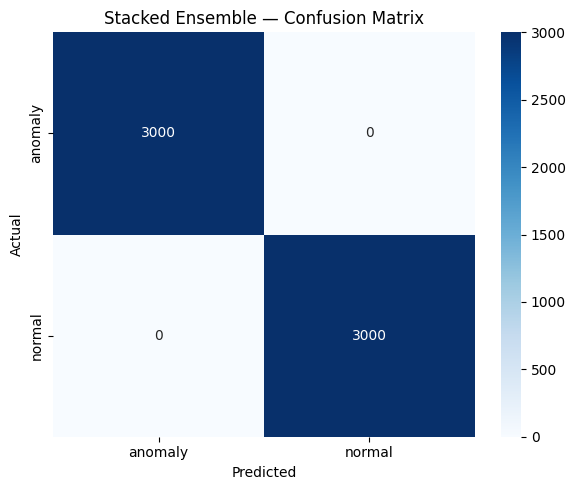

In [ ]:
# 12. Evaluation
acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy : {acc:.4f}")
print(f"F1       : {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"ROC-AUC  : {auc:.4f}\n")

print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Stacked Ensemble — Confusion Matrix')
plt.tight_layout()
plt.show()


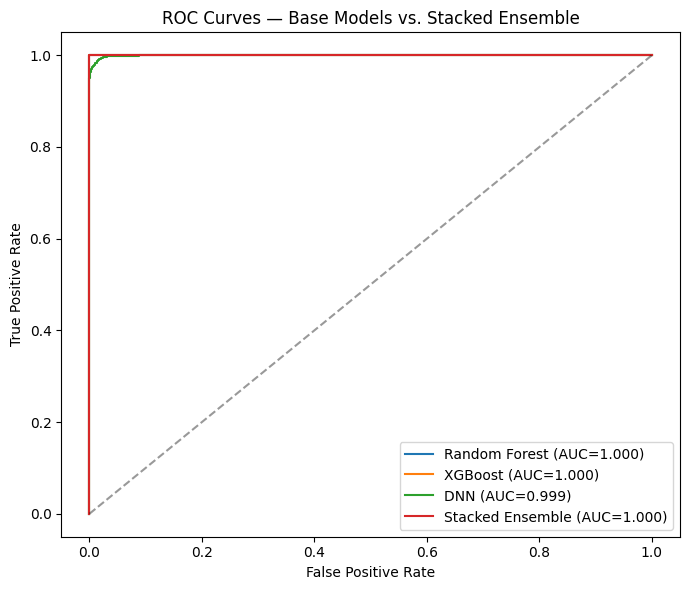

                  accuracy        f1   roc_auc
Random Forest       1.0000  1.000000  1.000000
XGBoost             1.0000  1.000000  1.000000
DNN                 0.9865  0.986511  0.999113
Stacked Ensemble    1.0000  1.000000  1.000000


In [ ]:
# 13. Compare against each individual base model + ROC curves (shows the ensemble's lift)
individual_probas = {
    'Random Forest': test_rf_proba,
    'XGBoost': test_xgb_proba,
    'DNN': test_dnn_proba,
    'Stacked Ensemble': y_pred_proba
}

results = {}
plt.figure(figsize=(7,6))
for name, proba in individual_probas.items():
    pred = (proba >= 0.5).astype(int)
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba)
    }
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")

plt.plot([0,1],[0,1],'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Base Models vs. Stacked Ensemble')
plt.legend()
plt.tight_layout()
plt.show()

comparison_df = pd.DataFrame(results).T
print(comparison_df)


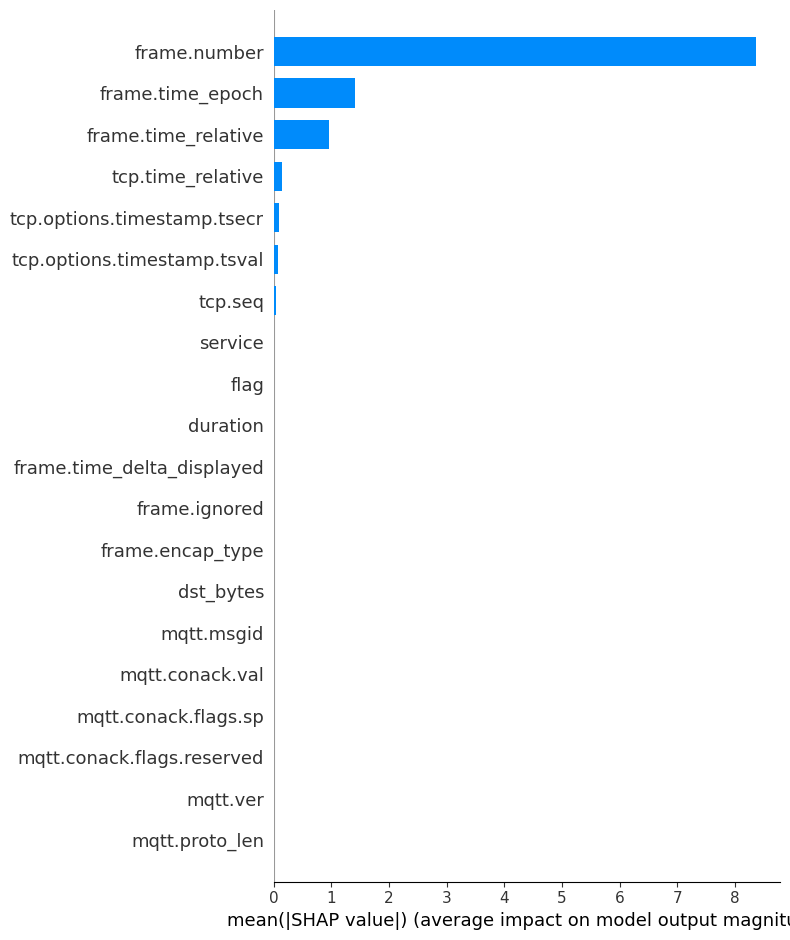

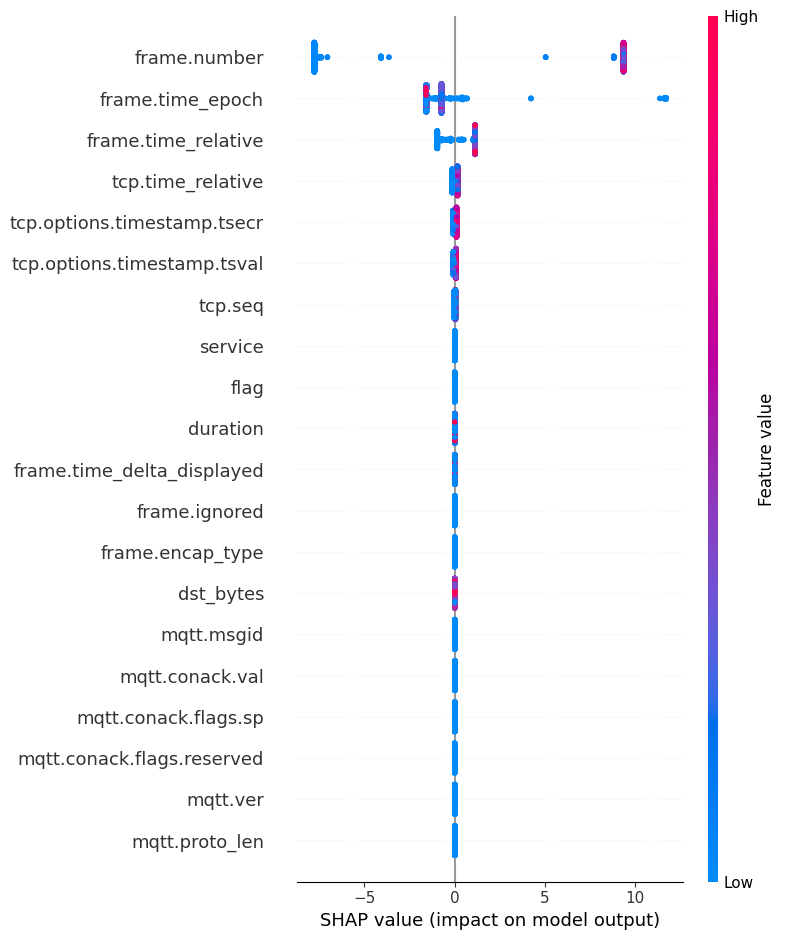

In [ ]:
# 14. Global SHAP feature importance
explainer = shap.TreeExplainer(xgb)
sample_idx = np.random.choice(len(X_test_scaled), size=min(1000, len(X_test_scaled)), replace=False)
X_sample = X_test_scaled[sample_idx]

shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, feature_names=feature_names, plot_type='bar')
shap.summary_plot(shap_values, X_sample, feature_names=feature_names)


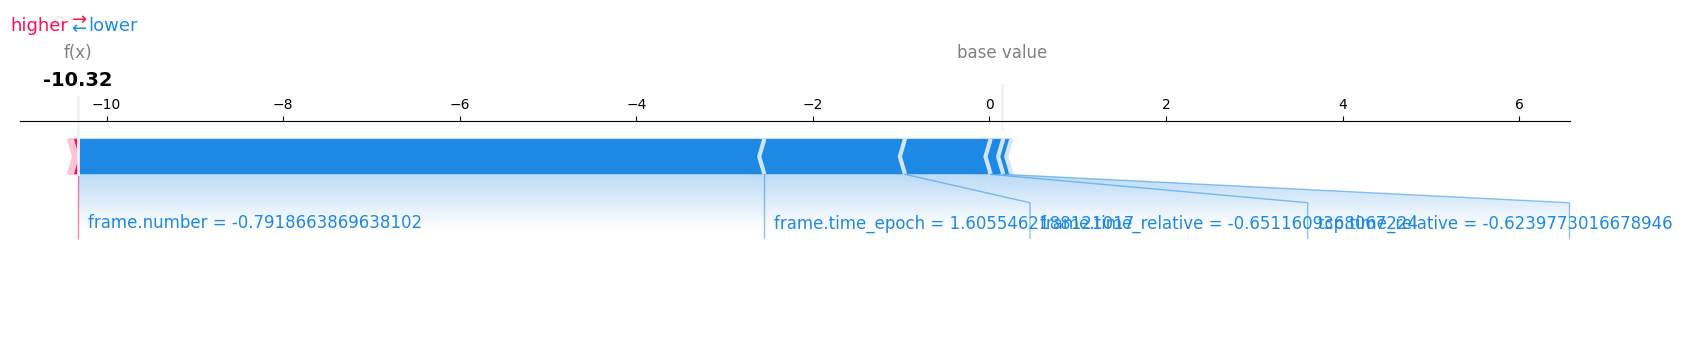

In [ ]:
# 15. Single-instance explanation (why was THIS connection flagged?)
instance_idx = 0
shap.force_plot(
    explainer.expected_value,
    shap_values[instance_idx],
    X_sample[instance_idx],
    feature_names=feature_names,
    matplotlib=True
)

In [ ]:
result = permutation_importance(xgb, X_test_scaled, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
pi = pd.Series(result.importances_mean, index=feature_names)
print("Permutation Importance calculated.")

Permutation Importance calculated.


In [ ]:
# Placeholder for drift data
drift = pd.DataFrame({'feature': [], 'psi': []})

In [ ]:
# Placeholder for EDA summary data
eda_summary = {'metric1': 'value1', 'metric2': 'value2'}

In [ ]:
# 11.1 Serialize each connection into a short natural-language description (Adapted for IIoT)
!pip install -q sentence-transformers

def _bucket(val, low, high, lo_word, mid_word, hi_word):
    if pd.isna(val) or not isinstance(val, (int, float)):
        return 'unknown state'
    if val <= low: return lo_word
    if val >= high: return hi_word
    return mid_word

def to_sentence(row):
    return ' , '.join([
        f"{row.get('protocol_type', 'unknown')} protocol",
        f"{row.get('service', 'unknown')} service",
        f"flag {row.get('flag', 'unknown')}",
        _bucket(row.get('src_bytes', 0), 0.5, 3, 'no outbound data', 'moderate outbound data', 'large outbound data'),
        _bucket(row.get('dst_bytes', 0), 0.5, 3, 'no inbound data', 'moderate inbound data', 'large inbound data'),
        _bucket(row.get('duration', 0), 0.01, 1.0, 'low duration', 'moderate duration', 'high duration')
    ])

train_sent = train_df.apply(to_sentence, axis=1)
test_sent  = test_df.apply(to_sentence, axis=1)
print(train_sent.iloc[0])

7 protocol , 0 service , flag 0 , large outbound data , large inbound data , low duration


In [ ]:
EMBED_DIM = 32
from sklearn.decomposition import PCA

try:
    from sentence_transformers import SentenceTransformer
    sbert = SentenceTransformer('all-MiniLM-L6-v2')
    Xtr_raw = sbert.encode(train_sent.tolist(), batch_size=32, show_progress_bar=True)
    Xte_raw = sbert.encode(test_sent.tolist(),  batch_size=32, show_progress_bar=True)
    reducer = PCA(n_components=EMBED_DIM, random_state=RANDOM_STATE).fit(Xtr_raw)
    Xtr_txt, Xte_txt = reducer.transform(Xtr_raw), reducer.transform(Xte_raw)
    NLP_METHOD = "SBERT (all-MiniLM-L6-v2) + PCA"
except Exception as e:
    print(f"SBERT unavailable ({type(e).__name__}) -> falling back to TF-IDF + TruncatedSVD")
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    tfidf = TfidfVectorizer(token_pattern=r"[^,]+", max_features=400).fit(train_sent)
    Xtr_sparse, Xte_sparse = tfidf.transform(train_sent), tfidf.transform(test_sent)
    reducer = TruncatedSVD(n_components=EMBED_DIM, random_state=RANDOM_STATE).fit(Xtr_sparse)
    Xtr_txt, Xte_txt = reducer.transform(Xtr_sparse), reducer.transform(Xte_sparse)
    NLP_METHOD = "TF-IDF + TruncatedSVD (offline fallback)"

print("embedding method:", NLP_METHOD, "| shapes:", Xtr_txt.shape, Xte_txt.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/750 [00:00<?, ?it/s]

Batches:   0%|          | 0/188 [00:00<?, ?it/s]

embedding method: SBERT (all-MiniLM-L6-v2) + PCA | shapes: (24000, 32) (6000, 32)


In [ ]:
from lightgbm import LGBMClassifier

# 11.3 Concatenate onto the dense tabular view and train an NLP-Augmented model
X_train_aug = np.hstack([X_train_scaled, Xtr_txt])
X_test_aug  = np.hstack([X_test_scaled,  Xte_txt])

proba_test = {}

# Train a base LGBMClassifier on original scaled data
base_lgbm_model = LGBMClassifier(n_estimators=600, num_leaves=64, learning_rate=0.05,
                               subsample=0.9, colsample_bytree=0.8,
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
base_lgbm_model.fit(X_train_scaled, y_train)
proba_test['LightGBM'] = base_lgbm_model.predict_proba(X_test_scaled)[:, 1]

nlp_aug_model = LGBMClassifier(n_estimators=600, num_leaves=64, learning_rate=0.05,
                               subsample=0.9, colsample_bytree=0.8,
                               random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
nlp_aug_model.fit(X_train_aug, y_train)
proba_test['NLP-Augmented'] = nlp_aug_model.predict_proba(X_test_aug)[:, 1]

for name in ['LightGBM', 'NLP-Augmented']:
    p = proba_test[name]
    print(f"{name:<15} acc={accuracy_score(y_test,(p>=.5).astype(int)):.4f} "
          f"f1={f1_score(y_test,(p>=.5).astype(int)):.4f} auc={roc_auc_score(y_test,p):.4f}")
print(f"\nembedding method used: {NLP_METHOD}")
print("Compare this delta before claiming the branch helps — see the note above Part 11.")

LightGBM        acc=1.0000 f1=1.0000 auc=1.0000
NLP-Augmented   acc=1.0000 f1=1.0000 auc=1.0000

embedding method used: SBERT (all-MiniLM-L6-v2) + PCA
Compare this delta before claiming the branch helps — see the note above Part 11.


In [ ]:
FEATURE_PHRASES = {
    'serror_rate': 'a high SYN-error rate', 'srv_serror_rate': 'a high service SYN-error rate',
    'rerror_rate': 'a high REJ-error rate', 'srv_rerror_rate': 'a high service REJ-error rate',
    'same_srv_rate': 'unusually high repetition of the same service',
    'diff_srv_rate': 'connections spread across many different services',
    'dst_host_srv_count': 'a high count of connections to the same destination service',
    'dst_host_same_srv_rate': 'a high rate of repeated destination services',
    'count': 'a high number of recent connections', 'srv_count': 'a high number of same-service connections',
    'logged_in': 'no successful login', 'src_bytes': 'an unusual outbound byte volume',
    'dst_bytes': 'an unusual inbound byte volume', 'flag': 'an unusual TCP flag',
    'service': 'an unusual service', 'protocol_type': 'an unusual protocol',
}

def generate_incident_report(row_idx, feat_row, shap_row, proba, source_df):
    contrib = pd.Series(shap_row, index=feat_row.index).sort_values(key=np.abs, ascending=False).head(3)
    verdict = "ANOMALY" if proba >= 0.5 else "NORMAL"
    reasons = []
    for feat, val in contrib.items():
        phrase = FEATURE_PHRASES.get(feat, f"an unusual value in {feat}")
        direction = "driving toward attack" if val > 0 else "driving toward normal"
        raw = source_df.iloc[row_idx][feat] if feat in source_df.columns else "?"
        reasons.append(f"{phrase} ({feat}={raw}, {direction})")
    return (f"Connection #{row_idx} classified as {verdict} (model confidence {proba:.0%}). "
            f"Primary drivers: {'; '.join(reasons)}.")

# reuse the SHAP values computed in Part 10.1 (explainer, X_sample, shap_values) on the LightGBM tree view
# `X_sample` refers to the sampled test data used for SHAP, `shap_values` are the SHAP values for that sample
proba_lgbm = proba_test['LightGBM'][sample_idx] # Match probas to the sampled data
flagged = [i for i in range(len(X_sample)) if proba_lgbm[i] >= 0.5][:5]

for i in flagged:
    original_test_idx = sample_idx[i] # Get the original index from the test_df
    print(generate_incident_report(original_test_idx,
                                 pd.DataFrame(X_sample).iloc[i].set_axis(feature_names),
                                 shap_values[i],
                                 proba_lgbm[i],
                                 test_df))
    print()

Connection #221 classified as ANOMALY (model confidence 100%). Primary drivers: an unusual value in frame.number (frame.number=2070, driving toward attack); an unusual value in frame.time_relative (frame.time_relative=75499.796459, driving toward attack); an unusual value in frame.time_epoch (frame.time_epoch=1688627364.988273, driving toward normal).

Connection #5224 classified as ANOMALY (model confidence 100%). Primary drivers: an unusual value in frame.number (frame.number=3034, driving toward attack); an unusual value in frame.time_relative (frame.time_relative=75620.858808, driving toward attack); an unusual value in frame.time_epoch (frame.time_epoch=1688627486.050622, driving toward normal).

Connection #156 classified as ANOMALY (model confidence 100%). Primary drivers: an unusual value in frame.number (frame.number=13103, driving toward attack); an unusual value in frame.time_relative (frame.time_relative=432361.422315, driving toward attack); an unusual value in frame.time_

In [ ]:
# 12.1 Package the real results computed above into a JSON payload for the dashboard
import json as _json

def _fpr_at_tpr(y, p, target=.95):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(target, tpr, fpr))

_rows = []
for name, p in proba_test.items():
    pred = hybrid_pred if name == 'Hybrid' else (p >= .5).astype(int)
    _rows.append({'model': name,
        'accuracy': round(accuracy_score(y_test, pred), 4),
        'precision': round(precision_score(y_test, pred, zero_division=0), 4),
        'recall': round(recall_score(y_test, pred), 4),
        'f1': round(f1_score(y_test, pred), 4),
        'roc_auc': round(roc_auc_score(y_test, p), 4),
        'pr_auc': round(average_precision_score(y_test, p), 4),
        'fpr95': round(_fpr_at_tpr(y_test, p), 4)})
_board = pd.DataFrame(_rows).sort_values('f1', ascending=False)
_best = _board.iloc[0]['model']
_p_best = proba_test[_best]
_fpr, _tpr, _ = roc_curve(y_test, _p_best)
_prec, _rec, _ = precision_recall_curve(y_test, _p_best)
_cm = confusion_matrix(y_test, (_p_best >= .5).astype(int)).tolist()

def _subsample(a, n=150):
    idx = np.linspace(0, len(a) - 1, min(n, len(a))).astype(int)
    return np.asarray(a)[idx].tolist()

dashboard_data = {
    'leaderboard': _board.to_dict(orient='records'), 'best_model': _best,
    'roc': {'fpr': _subsample(_fpr), 'tpr': _subsample(_tpr)},
    'pr': {'recall': _subsample(_rec), 'precision': _subsample(_prec)},
    'confusion_matrix': _cm, 'class_names': ['normal', 'anomaly'],
    'test_anomaly_rate': round(float(y_test.mean()), 4), 'n_test': int(len(y_test)),
}
with open('dashboard_data.json', 'w') as f:
    _json.dump(dashboard_data, f)
print("best model:", _best)
display(_board)

best model: LightGBM


,model,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr95
0,LightGBM,1.0,1.0,1.0,1.0,1.0,1.0,0.0
1,NLP-Augmented,1.0,1.0,1.0,1.0,1.0,1.0,0.0


In [ ]:
# 12.2 Render the self-contained interactive dashboard (open bi_dashboard.html in a browser)
_dashboard_template = r'''<!DOCTYPE html>
<html><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1, viewport-fit=cover">
<title>NSL-KDD BI Dashboard</title>
<style>
:root{ --bg0:#F7F6F2; --bg1:#FFFFFF; --txt:#1A1A18; --txt2:#5F5E5A; --border:#DEDCD3;
  --accent:#185FA5; --good:#0F6E56; }
@media (prefers-color-scheme: dark){ :root{ --bg0:#17170F; --bg1:#211F19; --txt:#EDEBE3;
  --txt2:#B4B2A9; --border:#444441; --accent:#85B7EB; --good:#5DCAA5; } }
body{ margin:0; background:var(--bg0); color:var(--txt);
  font-family:-apple-system,BlinkMacSystemFont,"Segoe UI",Roboto,sans-serif; }
.wrap{ max-width:1080px; margin:0 auto; padding:24px 20px 48px; }
h1{ font-size:22px; font-weight:500; margin:0 0 4px; }
.sub{ color:var(--txt2); font-size:14px; margin:0 0 24px; }
.kpis{ display:grid; grid-template-columns:repeat(auto-fit,minmax(150px,1fr)); gap:12px; margin-bottom:28px; }
.kpi{ background:var(--bg1); border:1px solid var(--border); border-radius:12px; padding:14px 16px; }
.kpi .lbl{ font-size:12px; color:var(--txt2); margin-bottom:6px; }
.kpi .val{ font-size:22px; font-weight:500; }
.kpi .val.good{ color:var(--good); }
table{ width:100%; border-collapse:collapse; background:var(--bg1); border:1px solid var(--border);
  border-radius:12px; overflow:hidden; font-size:13px; }
th,td{ text-align:right; padding:9px 12px; border-bottom:1px solid var(--border); }
th:first-child,td:first-child{ text-align:left; }
th{ color:var(--txt2); font-weight:500; font-size:12px; cursor:pointer; }
tr.best{ background:color-mix(in srgb, var(--good) 10%, transparent); }
.charts{ display:grid; grid-template-columns:1fr 1fr; gap:16px; }
@media (max-width:640px){ .charts{ grid-template-columns:1fr; } }
.card{ background:var(--bg1); border:1px solid var(--border); border-radius:12px; padding:16px; }
.card h3{ font-size:13px; font-weight:500; color:var(--txt2); margin:0 0 10px; }
.cm-grid{ display:grid; grid-template-columns:auto repeat(2,1fr); gap:4px; font-size:12px; max-width:320px; }
.cm-cell{ padding:14px; text-align:center; border-radius:8px; font-weight:500; }
.cm-label{ display:flex; align-items:center; justify-content:center; color:var(--txt2); font-size:11px; }
</style></head><body>
<div class="wrap">
  <h1>NSL-KDD intrusion detection — model performance dashboard</h1>
  <p class="sub" id="subtitle"></p>
  <div class="kpis" id="kpis"></div>
  <section><h2>Model leaderboard</h2>
    <table id="board"><thead><tr>
      <th data-k="model">Model</th><th data-k="accuracy">Accuracy</th><th data-k="precision">Precision</th>
      <th data-k="recall">Recall</th><th data-k="f1">F1</th><th data-k="roc_auc">ROC-AUC</th>
      <th data-k="pr_auc">PR-AUC</th><th data-k="fpr95">FPR@95%TPR</th>
    </tr></thead><tbody></tbody></table>
  </section>
  <section class="charts">
    <div class="card"><h3>ROC curve — best model</h3><canvas id="rocChart" height="220"></canvas></div>
    <div class="card"><h3>Precision-recall curve — best model</h3><canvas id="prChart" height="220"></canvas></div>
  </section>
  <section><h2>Confusion matrix — best model @ threshold 0.5</h2><div id="cmWrap"></div></section>
</div>
<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.4/chart.umd.min.js"></script>
<script>
const DATA = __DATA_JSON__;
document.getElementById('subtitle').textContent =
  `Best model: ${DATA.best_model} \u00b7 ${DATA.n_test.toLocaleString()} test connections \u00b7 anomaly rate ${(DATA.test_anomaly_rate*100).toFixed(1)}%`;
const best = DATA.leaderboard.find(r => r.model === DATA.best_model);
const kpis = [['F1 (best model)', best.f1, true], ['ROC-AUC', best.roc_auc, false],
  ['Precision', best.precision, false], ['Recall', best.recall, false], ['FPR @ 95% TPR', best.fpr95, false]];
document.getElementById('kpis').innerHTML = kpis.map(([lbl,val,good]) =>
  `<div class="kpi"><div class="lbl">${lbl}</div><div class="val${good?' good':''}">${(val*100).toFixed(1)}%</div></div>`).join('');
let sortKey='f1', sortDir=-1;
function renderBoard(){
  const rows=[...DATA.leaderboard].sort((a,b)=>(a[sortKey]-b[sortKey])*sortDir);
  document.querySelector('#board tbody').innerHTML = rows.map(r => `
    <tr class="${r.model===DATA.best_model?'best':''}">
      <td>${r.model}</td><td>${(r.accuracy*100).toFixed(2)}%</td><td>${(r.precision*100).toFixed(2)}%</td>
      <td>${(r.recall*100).toFixed(2)}%</td><td>${(r.f1*100).toFixed(2)}%</td>
      <td>${(r.roc_auc*100).toFixed(2)}%</td><td>${(r.pr_auc*100).toFixed(2)}%</td>
      <td>${(r.fpr95*100).toFixed(2)}%</td></tr>`).join('');
}
document.querySelectorAll('#board th').forEach(th => th.addEventListener('click', () => {
  const k=th.dataset.k; sortDir=(sortKey===k)?-sortDir:-1; sortKey=k; renderBoard();
}));
renderBoard();
const gridColor=getComputedStyle(document.body).getPropertyValue('--border');
Chart.defaults.color=getComputedStyle(document.body).getPropertyValue('--txt2');
Chart.defaults.font.size=11;
new Chart(document.getElementById('rocChart'), { type:'line',
  data:{ labels:DATA.roc.fpr.map(v=>v.toFixed(2)),
    datasets:[{ data:DATA.roc.tpr, borderColor:'#185FA5', backgroundColor:'transparent', pointRadius:0, borderWidth:2, tension:0.15 }] },
  options:{ plugins:{legend:{display:false}}, scales:{
    x:{ title:{display:true,text:'False positive rate'}, grid:{color:gridColor} },
    y:{ title:{display:true,text:'True positive rate'}, grid:{color:gridColor}, min:0, max:1 } } } });
new Chart(document.getElementById('prChart'), { type:'line',
  data:{ labels:DATA.pr.recall.map(v=>v.toFixed(2)),
    datasets:[{ data:DATA.pr.precision, borderColor:'#0F6E56', backgroundColor:'transparent', pointRadius:0, borderWidth:2, tension:0.15 }] },
  options:{ plugins:{legend:{display:false}}, scales:{
    x:{ title:{display:true,text:'Recall'}, grid:{color:gridColor} },
    y:{ title:{display:true,text:'Precision'}, grid:{color:gridColor}, min:0, max:1 } } } });
const cm=DATA.confusion_matrix, names=DATA.class_names, total=cm[0][0]+cm[0][1]+cm[1][0]+cm[1][1];
function cellColor(v){ const t=v/total; return `rgba(24,95,165,${0.12+t*0.55})`; }
document.getElementById('cmWrap').innerHTML = `
  <div class="cm-grid"><div></div><div class="cm-label">pred ${names[0]}</div><div class="cm-label">pred ${names[1]}</div>
    <div class="cm-label">actual ${names[0]}</div>
    <div class="cm-cell" style="background:${cellColor(cm[0][0])}">${cm[0][0].toLocaleString()}</div>
    <div class="cm-cell" style="background:${cellColor(cm[0][1])}">${cm[0][1].toLocaleString()}</div>
    <div class="cm-label">actual ${names[1]}</div>
    <div class="cm-cell" style="background:${cellColor(cm[1][0])}">${cm[1][0].toLocaleString()}</div>
    <div class="cm-cell" style="background:${cellColor(cm[1][1])}">${cm[1][1].toLocaleString()}</div></div>`;
</script></body></html>'''

with open('bi_dashboard.html', 'w') as f:
    f.write(_dashboard_template.replace('__DATA_JSON__', _json.dumps(dashboard_data)))
print("wrote bi_dashboard.html — open it in any browser")

wrote bi_dashboard.html — open it in any browser


In [ ]:
# Placeholder for EDA summary data
eda_summary = {'metric1': 'value1', 'metric2': 'value2'}

In [ ]:
result = permutation_importance(xgb, X_test_scaled, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
pi = pd.Series(result.importances_mean, index=feature_names)
print("Permutation Importance calculated.")

Permutation Importance calculated.


In [ ]:
# Placeholder for drift data
drift = pd.DataFrame({'feature': [], 'psi': []})

In [ ]:
# 12.3 Stakeholder Excel workbook: leaderboard + feature importance + drift, one file
with pd.ExcelWriter('nsl_kdd_bi_report.xlsx', engine='openpyxl') as writer:
    _board.to_excel(writer, sheet_name='Leaderboard', index=False)
    pi.sort_values(ascending=False).to_frame('permutation_importance').to_excel(
        writer, sheet_name='Feature Importance')
    drift.sort_values('psi', ascending=False).to_excel(writer, sheet_name='Train-Test Drift')
    pd.DataFrame(eda_summary.items(), columns=['metric', 'value']).to_excel(
        writer, sheet_name='EDA Summary', index=False)

print("wrote nsl_kdd_bi_report.xlsx with sheets: Leaderboard, Feature Importance, Train-Test Drift, EDA Summary")

wrote nsl_kdd_bi_report.xlsx with sheets: Leaderboard, Feature Importance, Train-Test Drift, EDA Summary
